# Per-locus features

This tutorial computes what describes a **locus across many cells** with `uchrom.fea`: population
distance maps (exact, in memory or streaming), contact frequencies and radii of gyration; the
axis-wise variance statistics the structure callers test; per-locus averages of per-spot imaging
signals projected onto the bin axis (`cd.bin_tracks`); peaks of such a signal; and gene-annotation
(GTF) and sequence (FASTA) features — every one recorded in `cd.uns["feature_registry"]`.

**Data** (all real):

- the Takei *et al.* 2021 mESC DNA seqFISH+ traces (*Nature* 590:344, 4DN `4DNFIHF3JCBY`, FOF-CT;
  20 loci × 60 bins × 25 kb): `ds.load("takei2021_mesc")` builds the `ChromData` once from the
  4DN files (core table 22 MB, with its cell and nascent-RNA tables);
- chromosome 19 of the Takei *et al.* 2025 cerebellum DNA seqFISH+ data with 59 immunofluorescence
  channels per spot (*Nature*, doi:10.1038/s41586-025-08838-x, Zenodo 7693825):
  `ds.load("takei2025_cerebellum")` opens the store of the public U-Chrom atlas over HTTP (built by
  `apps/atlas/recipes/build_takei2025_cerebellum.py`; only chromosome 19 and the channels used are fetched);
- the UCSC mm10 RefSeq gene annotation (`ds.fetch("mm10_refgene")`, 13 MB) and the UCSC mm10 chr19
  sequence (`ds.fetch("mm10_chr19")`, 19 MB), downloaded once from UCSC (reference files, not
  `ChromData`).

**Runtime**: about a minute on a laptop CPU once the files are downloaded.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from chromdata import ChromData
import uchrom
import uchrom.datasets as ds
import uchrom.fea as fea

plt.rcParams["figure.dpi"] = 90
OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

print("uchrom", uchrom.__version__)

uchrom 0.3.0.dev0


## 1. Population distance maps (Takei 2021 mESC)

`ds.load("takei2021_mesc")` gives the traces as a `ChromData` (one spot per row of the FOF-CT core
table).  Trace ids end in the allele (`_0`, `_1`, …); `_-1` marks spots that could not be assigned
to an allele — they are not a chromatin fibre, so we drop them before computing per-trace
statistics.

In [2]:
raw = ds.load("takei2021_mesc")      # built once from the 4DN FOF-CT tables, then read from the data directory
assigned = ~raw.spots["trace_id"].astype(str).str.endswith("_-1").to_numpy()
cd = raw[assigned]
print(f"dropped {(~assigned).sum():,} unassigned spots")
print(cd)
print("unit:", cd.uns["xyz_unit"], "| assembly:", cd.uns["genome_assembly"])

dropped 2,487 unassigned spots
ChromData: n_spots=314508, n_traces=7626, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  cells:   ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2', 'cytoplasm_area_um2', 'rna.Eef2', 'rna.Auts2', 'rna.Bdnf', 'rna.Clu', 'rna.Cx3cr1', 'rna.Efna5', 'rna.Npy', 'rna.S100b', 'rna.Slc17a7', 'rna.Stmn2', 'rna.Zfp42', 'rna.Myc', 'rna.Ccnd2', 'rna.Mcm2', 'rna.Mki67', 'rna.Sox2', 'rna.Nes', 'rna.Cdk1', 'rna.Mtf2', 'rna.Jade1', 'rna.Cenpa', 'rna.Aurka', 'rna.Plk1', 'rna.Mdm2', 'rna.Aebp2', 'rna.Tet1', 'rna.Nodal', 'rna.Tfcp2l1', 'rna.Tdh', 'rna.Sall4', 'rna.Nanog', 'rna.Esrrb', 'rna.Pou5f1', 'rna.Klf6', 'rna.Ctgf', 'rna.Peg10', 'rna.Myh9', 'rna.Tbx3', 'rna.Otx2', 'rna.Dnmt3a', 'rna.Dnmt3b', 'rna.Lin28a', 'rna.Lin28b', 'rna.Zscan4c', 'rna.Zfp352'] (201 cells)
  points:  {'rna': 3335}
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly', 'fofct_companions'

`distance_map(cd, chrom)` is the population **median** (or `stat="mean"`) 3-D distance of every
bin pair of one chromosome: per trace the Euclidean distance between its two spots, then reduced
over traces with missing spots skipped (a trace that observed a bin twice contributes its last
spot).  It returns a `DistanceMap` — a dict with attribute access: `matrix`, `count` (traces
observing each pair), `bins` (the rows), `n_traces`, and how it was computed.

In [3]:
chrom = "chr2"
dm = fea.distance_map(cd, chrom, stat="median")
print({k: dm[k] for k in ("chrom", "stat", "n_traces", "streaming", "n_passes", "n_bands")})
print("matrix", dm.matrix.shape, "| traces per pair: median", int(np.median(dm.count[np.triu_indices(60, 1)])))
dm.bins.head(3)

{'chrom': 'chr2', 'stat': 'median', 'n_traces': 390, 'streaming': False, 'n_passes': 2, 'n_bands': 1}
matrix (60, 60) | traces per pair: median 124


,bin_id,chrom,start,end
0,660,chr2,109000000,109025000
1,661,chr2,109025000,109050000
2,662,chr2,109050000,109075000


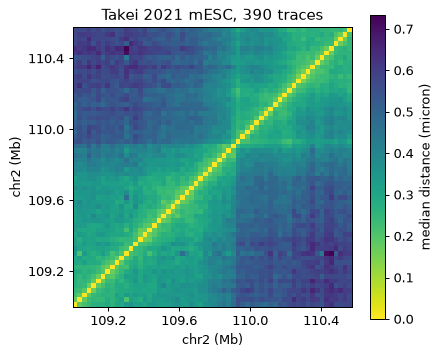

In [4]:
mb = dm.bins["start"].to_numpy() / 1e6
extent = [mb[0], mb[-1] + 0.025, mb[0], mb[-1] + 0.025]
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(dm.matrix, cmap="viridis_r", origin="lower", extent=extent)
fig.colorbar(im, ax=ax, label=f"median distance ({cd.uns['xyz_unit']})")
ax.set_xlabel(f"{chrom} (Mb)"); ax.set_ylabel(f"{chrom} (Mb)")
ax.xaxis.set_major_locator(MaxNLocator(4)); ax.yaxis.set_major_locator(MaxNLocator(4))
ax.set_title(f"Takei 2021 mESC, {dm.n_traces} traces")
fig.tight_layout(); plt.show()

`mean_distance_matrix(cd, chrom=...)` is the dense reference: it builds the
`(n_traces, n_bins, n_bins)` tensor of the chromosome's traces.  Same definition, so the median maps
are identical; `distance_map` never builds the tensor and therefore also runs on genome-wide data.

In [5]:
ref, ref_bins, n_ref = fea.mean_distance_matrix(cd, chrom=chrom, reduce="median")
print("median maps identical:", np.array_equal(ref, dm.matrix, equal_nan=True), "| traces:", n_ref)
ref_mean, _, _ = fea.mean_distance_matrix(cd, chrom=chrom, reduce="mean")
dm_mean = fea.distance_map(cd, chrom, stat="mean")
print(f"mean maps: max |difference| = {np.nanmax(np.abs(ref_mean - dm_mean.matrix)):.1e} {cd.uns['xyz_unit']}")

median maps identical: True | traces: 390
mean maps: max |difference| = 0.0e+00 micron


### Streaming over a store

On a store opened with `backed=True`, `distance_map` streams the traces in batches
(`iter_traces(chrom=..., columns="coords")`) and computes the exact median one row band of the
matrix at a time, so memory is bounded by `memory_budget` (default
`uchrom.settings.memory_budget`), not by the number of traces.  A deliberately small budget forces
several bands; the result is the same matrix.

In [6]:
store = OUT / "takei2021_mesc.chromdata.zarr"
cd.write(store)
backed = ChromData.read(store, backed=True)
dm_s = fea.distance_map(backed, chrom, memory_budget="64MB")
print({k: dm_s[k] for k in ("streaming", "n_passes", "n_bands")})
print("identical to the in-memory map:", np.array_equal(dm_s.matrix, dm.matrix, equal_nan=True))

{'streaming': True, 'n_passes': 3, 'n_bands': 2}
identical to the in-memory map: True


### Contact frequency, distance scaling and radius of gyration

`contact_frequency(cd, threshold, chrom=...)` is the fraction of traces (that observed both bins)
in which two bins are closer than `threshold` (computed pair by pair like `distance_map`, so it also
streams over a backed store).  We use the median distance between adjacent 25-kb bins as the
threshold.  The decay of the median distance with genomic separation is read off the diagonals of
the distance map, and `radius_of_gyration(cd, chrom=...)` gives one Rg per trace.

median adjacent-bin distance 0.184 micron -> threshold 0.18
contact frequency: adjacent bins 0.49, bins 1 Mb apart 0.02
median distance ~ separation^0.32 over 25 kb - 1.5 Mb


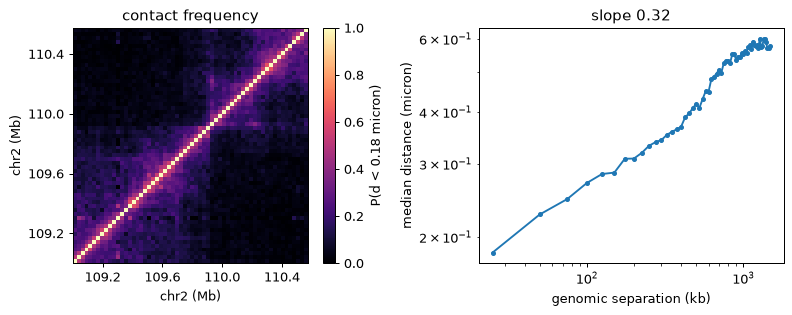

In [7]:
adjacent = float(np.nanmedian(np.diag(dm.matrix, 1)))
threshold = round(adjacent, 2)
freq, _, _ = fea.contact_frequency(cd, threshold, chrom=chrom)
print(f"median adjacent-bin distance {adjacent:.3f} {cd.uns['xyz_unit']} -> threshold {threshold}")
print(f"contact frequency: adjacent bins {np.nanmean(np.diag(freq, 1)):.2f}, "
      f"bins 1 Mb apart {np.nanmean(np.diag(freq, 40)):.2f}")

sep_kb = 25 * np.arange(1, 60)
med_by_sep = np.array([np.nanmedian(np.diag(dm.matrix, k)) for k in range(1, 60)])
slope = np.polyfit(np.log10(sep_kb), np.log10(med_by_sep), 1)[0]
print(f"median distance ~ separation^{slope:.2f} over 25 kb - 1.5 Mb")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
im = axes[0].imshow(freq, cmap="magma", origin="lower", vmin=0, vmax=1, extent=extent)
fig.colorbar(im, ax=axes[0], label=f"P(d < {threshold} {cd.uns['xyz_unit']})")
axes[0].set_xlabel(f"{chrom} (Mb)"); axes[0].set_ylabel(f"{chrom} (Mb)"); axes[0].set_title("contact frequency")
axes[0].xaxis.set_major_locator(MaxNLocator(4)); axes[0].yaxis.set_major_locator(MaxNLocator(4))
axes[1].loglog(sep_kb, med_by_sep, "o-", ms=3)
axes[1].set_xlabel("genomic separation (kb)"); axes[1].set_ylabel(f"median distance ({cd.uns['xyz_unit']})")
axes[1].set_title(f"slope {slope:.2f}")
fig.tight_layout(); plt.show()

In [8]:
rg = pd.concat({c: fea.radius_of_gyration(cd, chrom=c) for c in cd.chroms}, names=["chrom", "trace_id"])
rg_table = rg.groupby(level="chrom", sort=False).agg(["count", "median"]).rename(columns={"count": "traces", "median": "median Rg"})
print(f"{rg.notna().sum():,} traces; median Rg {rg.median():.3f} {cd.uns['xyz_unit']} "
      f"(per-locus medians {rg_table['median Rg'].min():.2f}-{rg_table['median Rg'].max():.2f})")
rg_table.sort_values("median Rg").T.round(3)

7,626 traces; median Rg 0.323 micron (per-locus medians 0.27-0.42)


chrom,chr18,chr6,chr5,chr4,chr15,chr17,chr14,chr12,chr3,chr2,chr8,chrX,chr16,chr9,chr10,chr1,chr13,chr19,chr11,chr7
traces,404.000,383.000,382.000,396.000,381.000,396.000,388.000,394.000,392.000,390.000,405.000,198.000,381.000,391.000,388.000,386.000,393.000,393.000,404.000,381.000
median Rg,0.272,0.281,0.282,0.293,0.296,0.301,0.306,0.311,0.314,0.318,0.325,0.329,0.329,0.336,0.337,0.343,0.376,0.383,0.397,0.422


## 2. Axis-wise variance features (what the callers test)

The ArcFISH-style callers in `uchrom.strc` (loops, TADs, compartments) do not test distances but
the **variance of the coordinate difference along each axis** — imaging error differs between x/y
and z, and a pair of loci that moves together has a small variance.  `uchrom.fea` exposes the
three building blocks:

- `axis_variance_cube(cd, chrom)` — per-axis `(3, n_bins, n_bins)` variance and count cubes;
- `filter_normalize(cube)` — drops per-trace outliers (beyond `k_sigma` × the distance-stratified
  spread) and divides by a LOWESS fit over genomic distance, so `norm_var` is ~1 on average at
  every separation;
- `axis_weight(cd, chrom)` — the weights of the three axes when the per-axis tests are combined
  (inversely proportional to each axis's median per-trace variance).

`device="auto"` picks CUDA / MPS when available; we use the CPU here.

In [9]:
t = time.time()
cube = fea.axis_variance_cube(cd, chrom, device="cpu")
norm = fea.filter_normalize(cube, k_sigma=4.0, frac=0.1)
w = fea.axis_weight(cd, chrom, device="cpu")
print(f"{time.time() - t:.1f} s; cubes {norm['var'].shape} over {cube['n_traces']} traces")

iu = np.triu_indices(60, 1)
n_before, n_after = cube["count"][(slice(None),) + iu].sum(), norm["count"][(slice(None),) + iu].sum()
print(f"outlier observations removed: {n_before - n_after:,} of {n_before:,} ({(n_before - n_after) / n_before:.2%})")
print("axis weights x, y, z:", np.round(w, 3))
d = norm["genomic_distance"]
for a, name in enumerate("xyz"):
    e = norm["expected"][a]
    print(f"  {name}: expected variance {np.nanmedian(e[np.isclose(d, 25_000)]):.4f} at 25 kb, "
          f"{np.nanmedian(e[np.isclose(d, 1_000_000)]):.4f} at 1 Mb")

1.2 s; cubes (3, 60, 60) over 390 traces
outlier observations removed: 14,741 of 639,558 (2.30%)
axis weights x, y, z: [0.273 0.29  0.437]
  x: expected variance 0.0158 at 25 kb, 0.1366 at 1 Mb
  y: expected variance 0.0135 at 25 kb, 0.1570 at 1 Mb
  z: expected variance 0.0115 at 25 kb, 0.0596 at 1 Mb


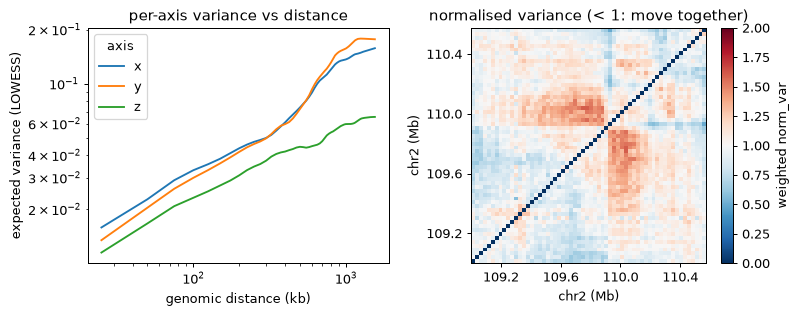

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for a, name in enumerate("xyz"):
    order = np.argsort(d[iu])
    axes[0].loglog(d[iu][order] / 1e3, norm["expected"][a][iu][order], label=name)
axes[0].set_xlabel("genomic distance (kb)"); axes[0].set_ylabel("expected variance (LOWESS)")
axes[0].legend(title="axis"); axes[0].set_title("per-axis variance vs distance")
im = axes[1].imshow(np.average(norm["norm_var"], axis=0, weights=w), cmap="RdBu_r", vmin=0, vmax=2,
                    origin="lower", extent=extent)
fig.colorbar(im, ax=axes[1], label="weighted norm_var")
axes[1].set_xlabel(f"{chrom} (Mb)"); axes[1].set_ylabel(f"{chrom} (Mb)")
axes[1].xaxis.set_major_locator(MaxNLocator(4)); axes[1].yaxis.set_major_locator(MaxNLocator(4))
axes[1].set_title("normalised variance (< 1: move together)")
fig.tight_layout(); plt.show()

In this dataset the traces are least extended along z, so z gets the largest weight.  The loop caller then F-tests `norm_var` of each pair against its local
background; see the `loop_calling` and `tad_calling` tutorials.

## 3. Per-spot signals → per-locus tracks (Takei 2025 cerebellum, chr19)

The Takei 2025 store has 10.9 M spots at 100,049 genome-wide 25-kb loci and 59
immunofluorescence (IF) / repeat / RNA channels **per spot** (`cd.spot_tracks`): the intensity of
a nuclear mark around that DNA locus in that cell.  `ds.load("takei2025_cerebellum")` opens the
store of the public U-Chrom atlas backed, over HTTP: the small tables are read at open, and range
requests later fetch only chromosome 19 (a few seconds) — not the whole store.

In [11]:
full = ds.load("takei2025_cerebellum")           # the atlas store, backed: nothing spot-aligned is read yet
print(f"{full.n_spots:,} spots, {full.n_cells:,} cells, {full.n_bins:,} bins, "
      f"{len(full.spot_tracks.columns)} spot tracks, assembly {full.uns['genome_assembly']}")

10,912,638 spots, 1,799 cells, 100,049 bins, 62 spot tracks, assembly mm10


The streaming distance map is what makes such a store tractable: chr19 has 2,326 bins, and the
median over its traces is computed band by band straight from the backed store.  At 25 kb
each trace observes only a few percent of the loci, so most pairs are seen by a handful of
traces; `DistanceMap.coarsen(20)` pools the map into blocks of 20 × 20 bins (500 kb) for
display (the median of each block's distances, the zero self-distances left out).  (The default
traces of this dataset can merge the two homologs — see the catalog entry — which inflates
long-range distances.)

18.3 s: 2,326 bins, 2,175 traces, streaming=True, 12 bands; traces per pair: median 3


117 blocks of 20 bins (the last one 6)


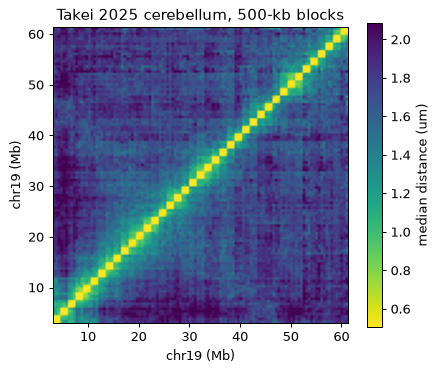

In [12]:
t = time.time()
dm19 = fea.distance_map(full, "chr19", memory_budget="256MB")
print(f"{time.time() - t:.1f} s: {dm19.matrix.shape[0]:,} bins, {dm19.n_traces:,} traces, "
      f"streaming={dm19.streaming}, {dm19.n_bands} bands; traces per pair: median "
      f"{np.median(dm19.count[np.triu_indices(len(dm19.matrix), 1)]):.0f}")

blocks = dm19.coarsen(20)                       # 20 x 25 kb = 500-kb blocks
print(f"{len(blocks.matrix)} blocks of {blocks.block_size} bins (the last one {blocks.bins['n_bins'].iloc[-1]})")
lo, hi = blocks.bins["start"].iloc[0] / 1e6, blocks.bins["end"].iloc[-1] / 1e6
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(blocks.matrix, cmap="viridis_r", origin="lower", extent=[lo, hi, lo, hi],
               vmin=np.nanpercentile(blocks.matrix, 2), vmax=np.nanpercentile(blocks.matrix, 98))
fig.colorbar(im, ax=ax, label=f"median distance ({full.uns['xyz_unit']})")
ax.set_xlabel("chr19 (Mb)"); ax.set_ylabel("chr19 (Mb)"); ax.set_title("Takei 2025 cerebellum, 500-kb blocks")
fig.tight_layout(); plt.show()

Now the signals.  `get_chrom(..., tracks=...)` reads the chromosome with just the channels we
need; `rebuild_bins()` keeps only the loci those spots observe (2,326 chr19 bins instead of the
genome's 100,049).  `aggregate_tracks_by_interval` averages each per-spot track over the spots of
every locus (all cells, all traces) and `project_interval_features_to_bins` writes the result on
the bin axis, `cd.bin_tracks`, under a prefix (with `if.n_spots`, the spots behind each mean).

In [13]:
marks = ["H3K4me3", "H3K27ac", "RNAPIISer5-P", "H3K9me3", "H3K27me3", "LaminB1"]
c19 = full.get_chrom("chr19", tracks=marks).rebuild_bins()
print(c19)

per_locus = fea.aggregate_tracks_by_interval(c19, marks, agg="mean")
print(f"{len(per_locus):,} loci; spots per locus: median {per_locus['n_spots'].median():.0f} "
      f"(min {per_locus['n_spots'].min()}, max {per_locus['n_spots'].max()})")
c19.bin_tracks = fea.project_interval_features_to_bins(c19, per_locus, prefix="if", into=c19.bin_tracks)
c19.bin_tracks.head(3).round(3)

ChromData: n_spots=178766, n_traces=2175, n_cells=1531, n_bins=2326
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'name', 'bin_id']
  cells:   ['leiden', 'cell_type', 'x_centroid', 'y_centroid', 'z_centroid', 'nuc_volume_um3', 'doublet', 'batch'] (1531 cells)
  cellm:   {'umap': (1531, 2)}
  spot_tracks:    ['H3K9me3', 'LaminB1', 'RNAPIISer5-P', 'H3K27ac', 'H3K4me3', 'H3K27me3']
  traces:  ['dbscan_allele', 'dbscan_ldp_allele'] (2175 traces)
  uns:     ['allele_col', 'genome_assembly', 'keep_unclustered', 'source', 'voxel_xy_nm', 'voxel_z_nm', 'xyz_unit', 'zenodo_record', 'leiden_to_cell_type', 'fovs']
2,326 loci; spots per locus: median 74 (min 9, max 216)


,if.H3K4me3,if.H3K27ac,if.RNAPIISer5-P,if.H3K9me3,if.H3K27me3,if.LaminB1,if.n_spots
bin_id,,,,,,,
0,1.667,1.205,1.287,-0.053,0.183,0.030,28
1,2.007,1.228,1.548,-0.077,0.441,-0.395,41
2,1.828,0.994,1.586,-0.059,0.373,-0.165,44


In [14]:
rho = c19.bin_tracks[[f"if.{m}" for m in marks]].corr(method="spearman")
rho.index = rho.columns = marks
rho.round(2)

,H3K4me3,H3K27ac,RNAPIISer5-P,H3K9me3,H3K27me3,LaminB1
H3K4me3,1.00,0.91,0.96,-0.73,0.10,-0.54
H3K27ac,0.91,1.00,0.96,-0.76,0.12,-0.39
RNAPIISer5-P,0.96,0.96,1.00,-0.77,0.15,-0.47
H3K9me3,-0.73,-0.76,-0.77,1.00,-0.06,0.32
H3K27me3,0.10,0.12,0.15,-0.06,1.00,-0.09
LaminB1,-0.54,-0.39,-0.47,0.32,-0.09,1.00


Across chr19 loci the active marks (H3K4me3, H3K27ac, initiating Pol II) rise and fall together
and opposite to H3K9me3 / lamina; H3K27me3 is nearly independent of both.

`aggregate_tracks_by_interval` does not register what it computed; `append_feature_registry_entry`
records your own features in the same registry the built-in writers use.

In [15]:
fea.append_feature_registry_entry(c19, {
    "feature_group": "spot_track_mean",
    "features": [f"if.{m}" for m in marks] + ["if.n_spots"],
    "parameters": {"aggregation": "mean", "source": "cd.spot_tracks", "chrom": "chr19"},
    "created_by": "features tutorial",
})
c19.uns["feature_registry"][-1]

{'feature_group': 'spot_track_mean',
 'features': ['if.H3K4me3',
  'if.H3K27ac',
  'if.RNAPIISer5-P',
  'if.H3K9me3',
  'if.H3K27me3',
  'if.LaminB1',
  'if.n_spots'],
 'parameters': {'aggregation': 'mean',
  'source': 'cd.spot_tracks',
  'chrom': 'chr19'},
 'created_by': 'features tutorial',
 'created_utc': '2026-10-07T18:15:18+00:00',
 'uchrom_version': '0.3.0.dev0',
 'n_features': 7}

## 4. Peaks of a per-locus signal

`call_peaks_from_track(cd, track, method=...)` aggregates a track per locus, calls peaks and
writes three features per bin (`peak.<name>_overlap`, `_count`, `distance_to_<name>`) to
`cd.bin_tracks`; the peak table goes to `cd.results["peaks:<name>"]`.  Methods: `"threshold"`
(contiguous bins above a value or quantile), `"macs"` (a port of MACS3 `bdgpeakcall`: bins at or
above `cutoff`, merged across gaps ≤ `max_gap` bp, at least `min_length` bp) and
`"macs_poisson"` (dynamic local-lambda Poisson test, optionally against a `control_track`).

IF intensities are z-scored per spot, so the cutoff is on that scale: we take the chromosome's
median locus value + 2 robust SDs (1.4826 × MAD), require two bins (50 kb) and bridge one-bin gaps.
These IF "peaks" are loci that sit in an H3K4me3-rich nuclear neighbourhood, not ChIP-seq peaks.

In [16]:
v = per_locus["H3K4me3"]
center, spread = v.median(), 1.4826 * (v - v.median()).abs().median()
cutoff = float(center + 2 * spread)
peaks = fea.call_peaks_from_track(c19, "H3K4me3", method="macs", cutoff=cutoff,
                                  min_length=50_000, max_gap=25_000)
print(f"cutoff {cutoff:.3f}: {len(peaks)} peaks covering {(peaks['end'] - peaks['start']).sum() / 1e6:.2f} Mb "
      f"({c19.bin_tracks['peak.h3k4me3_overlap'].sum():.0f} of {c19.n_bins:,} loci)")
print("results:", list(c19.results.keys()))
peaks[["peak_id", "chrom", "start", "end", "n_bins", "score", "mean_signal", "summit"]]

cutoff 1.579: 9 peaks covering 5.60 Mb (220 of 2,326 loci)
results: ['peaks:h3k4me3', 'bin_features']


,peak_id,chrom,start,end,n_bins,score,mean_signal,summit
0,h3k4me3_1,chr19,3050000,3125000,3,2.007176,1.833974,3087500
1,h3k4me3_2,chr19,3475000,7625000,162,2.585290,2.047956,5112500
2,h3k4me3_3,chr19,45275000,45325000,2,1.699492,1.698749,45287500
3,h3k4me3_4,chr19,45375000,45425000,2,1.673454,1.669143,45412500
4,h3k4me3_5,chr19,45475000,45675000,7,1.942982,1.731808,45637500
5,h3k4me3_6,chr19,45725000,46300000,21,1.853214,1.725412,46262500
6,h3k4me3_7,chr19,46375000,46725000,11,2.030440,1.757750,46562500
7,h3k4me3_8,chr19,46875000,46950000,2,1.625147,1.623102,46937500
8,h3k4me3_9,chr19,47000000,47075000,3,1.645112,1.609127,47037500


Most peaks are a few hundred kb; one is a 4-Mb block (3.5–7.6 Mb), the gene-dense end of chr19,
where the whole region sits in an H3K4me3-rich neighbourhood (see the tracks below).

The lower-level `call_macs_bdgpeaks_from_signal` takes any per-locus table (`chrom, start, end`
+ a score column) — here the robust z-score of the same signal with `cutoff=2`, which must give
the same intervals — and `macs_bdgpeaks_to_narrowpeak` renders the result as a narrowPeak file
for a genome browser.  Storing the table in `cd.intervals` (kind `peak`) lets the U-Chrom web
browser draw it as an interval row.

In [17]:
scored = per_locus[["chrom", "start", "end"]].assign(score=(v - center) / spread)
peaks_z = fea.call_macs_bdgpeaks_from_signal(scored, signal_col="score", cutoff=2.0,
                                             min_length=50_000, max_gap=25_000, name="H3K4me3")
same = peaks_z[["start", "end"]].reset_index(drop=True).equals(peaks[["start", "end"]].reset_index(drop=True))
print("same intervals as call_peaks_from_track:", same)
narrow = OUT / "takei2025_chr19_H3K4me3.narrowPeak"
narrow.write_text(fea.macs_bdgpeaks_to_narrowpeak(peaks_z, name="H3K4me3"))
print(narrow); print("".join(narrow.read_text().splitlines(True)[:3]))

c19.intervals.add("peaks.h3k4me3", peaks, kind="peak", source_result="peaks:h3k4me3")
in_peak = c19.intervals.to_bins("peaks.h3k4me3", c19.bins, how="bool")
print("IntervalTable.to_bins agrees with peak.h3k4me3_overlap:",
      np.array_equal(in_peak.to_numpy(), c19.bin_tracks["peak.h3k4me3_overlap"].to_numpy() == 1))

same intervals as call_peaks_from_track: True
_out/takei2025_chr19_H3K4me3.narrowPeak


chr19	3050000	3125000	H3K4me3_narrowPeak1	28	.	0	0	0	37500
chr19	3475000	7625000	H3K4me3_narrowPeak2	40	.	0	0	0	1637500
chr19	45275000	45325000	H3K4me3_narrowPeak3	22	.	0	0	0	12500

IntervalTable.to_bins agrees with peak.h3k4me3_overlap: True


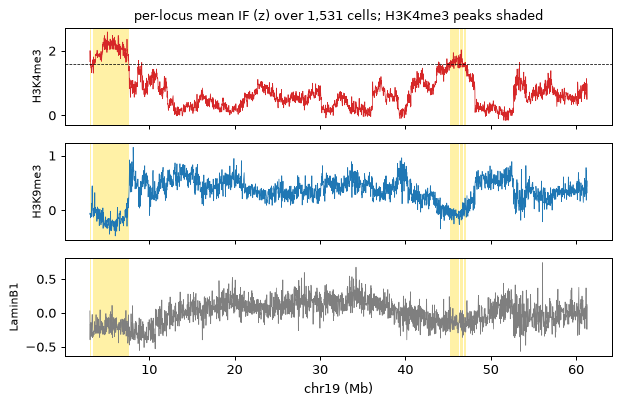

In [18]:
x = c19.bins["start"].to_numpy() / 1e6
fig, axes = plt.subplots(3, 1, figsize=(7, 4.6), sharex=True)
for ax, m, colour in zip(axes, ["H3K4me3", "H3K9me3", "LaminB1"], ["C3", "C0", "C7"]):
    ax.plot(x, c19.bin_tracks[f"if.{m}"], lw=0.6, color=colour)
    ax.set_ylabel(m, fontsize=9)
    for _, p in peaks.iterrows():
        ax.axvspan(p["start"] / 1e6, p["end"] / 1e6, color="gold", alpha=0.35, lw=0)
axes[0].axhline(cutoff, color="k", lw=0.6, ls="--")
axes[-1].set_xlabel("chr19 (Mb)")
axes[0].set_title(f"per-locus mean IF (z) over {c19.n_cells:,} cells; H3K4me3 peaks shaded", fontsize=10)
fig.tight_layout(); plt.show()

## 5. Annotation (GTF) and sequence (FASTA) features

`add_annotation_features(cd, gtf)` computes per bin: gene-body / exon / promoter
(−2 kb … +0.5 kb of the TSS) overlap in bp and as a fraction, the number of genes, and the
distance to the nearest TSS.  It reads `gene` and `exon` rows of a GTF path or of a table from
`read_gtf`.  The UCSC mm10 RefSeq GTF has transcripts but no `gene` rows; `read_gtf` then adds them
itself (`fea.gene_bodies`): one gene body per place where a gene's transcripts overlap (a gene name
can occur at several places).

In [19]:
GTF = ds.fetch("mm10_refgene")                  # UCSC mm10 refGene GTF (13 MB; downloaded once)
t = time.time()
gtf = fea.read_gtf(GTF)                         # + gene rows derived from the transcripts
on19 = gtf[gtf["chrom"] == "chr19"]["feature"].value_counts()
print(f"{on19['gene']} chr19 genes, {on19['exon']:,} exons")

ann = fea.add_annotation_features(c19, gtf)
print(f"{time.time() - t:.1f} s"); ann.drop(columns=["chrom", "start", "end"]).describe().loc[["mean", "50%", "max"]].round(3)

815 chr19 genes, 14,101 exons


4.4 s


,gene_body_overlap_bp,gene_body_overlap_fraction,gene_count,exon_overlap_bp,exon_overlap_fraction,promoter_overlap_bp,promoter_overlap_fraction,nearest_tss_distance
mean,12368.102,0.495,0.858,955.059,0.038,824.108,0.033,96587.617
50%,12860.000,0.514,1.000,115.000,0.005,0.000,0.000,24824.000
max,25000.000,1.000,8.000,20480.000,0.819,12836.000,0.513,1218976.000


`add_sequence_features(cd, fasta)` computes GC fraction, CpG density, N fraction and G-quadruplex
motif counts per bin from a (gzipped) FASTA whose record names are the chromosome names.  It
needs only the chromosomes of the bins: the UCSC mm10 `chr19.fa.gz` (19 MB, `ds.fetch("mm10_chr19")`)
suffices here.

In [20]:
FASTA = ds.fetch("mm10_chr19")                  # UCSC mm10 chr19 sequence (19 MB; downloaded once)
t = time.time()
seq = fea.add_sequence_features(c19, FASTA)
print(f"{time.time() - t:.1f} s"); seq.drop(columns=["chrom", "start", "end"]).describe().loc[["mean", "50%", "max"]].round(4)

2.4 s


,gc_fraction,cpg_density,n_fraction,g4_motif_count,g4_motif_density
mean,0.4273,0.0096,0.0004,11.0387,0.0004
50%,0.4207,0.0087,0.0000,8.0000,0.0003
max,0.5583,0.0298,0.5446,143.0000,0.0057


### Do the imaging signals agree with the genome?

A check on real data: loci in H3K4me3 peaks should be gene- and promoter-rich and GC-rich, and
the active marks should correlate with GC content and promoter density, the repressive ones
against them.

In [21]:
bt = c19.bin_tracks
inside = bt["peak.h3k4me3_overlap"] == 1
summary = pd.DataFrame({
    "in H3K4me3 peaks": [inside.sum(), (bt["gtf.promoter_overlap_bp"] > 0)[inside].mean(),
                          bt["gtf.gene_count"][inside].mean(), bt["seq.gc_fraction"][inside].median()],
    "other loci": [(~inside).sum(), (bt["gtf.promoter_overlap_bp"] > 0)[~inside].mean(),
                   bt["gtf.gene_count"][~inside].mean(), bt["seq.gc_fraction"][~inside].median()],
}, index=["loci", "fraction with a promoter", "genes per locus", "median GC"])
display(summary.round(3))

rows = {}
for m in marks:
    rows[m] = {f: spearmanr(bt[f"if.{m}"], bt[f], nan_policy="omit")[0]
               for f in ["seq.gc_fraction", "seq.cpg_density", "gtf.promoter_overlap_fraction", "gtf.nearest_tss_distance"]}
pd.DataFrame(rows).T.round(2)

,in H3K4me3 peaks,other loci
loci,220.000,2106.000
fraction with a promoter,0.609,0.243
genes per locus,1.691,0.771
median GC,0.485,0.417


,seq.gc_fraction,seq.cpg_density,gtf.promoter_overlap_fraction,gtf.nearest_tss_distance
H3K4me3,0.68,0.61,0.31,-0.46
H3K27ac,0.67,0.62,0.23,-0.36
RNAPIISer5-P,0.70,0.64,0.27,-0.40
H3K9me3,-0.64,-0.59,-0.22,0.33
H3K27me3,0.16,0.16,-0.17,0.15
LaminB1,-0.34,-0.25,-0.21,0.25


## 6. The feature registry and persistence

Every writer appended a provenance record to `cd.uns["feature_registry"]`: the feature group,
the columns it wrote, the parameters, the source file, the U-Chrom version and a timestamp.  The
interval tables behind the bin features are in `cd.results["bin_features"]` (one row per locus).

In [22]:
reg = pd.DataFrame(c19.uns["feature_registry"])
display(reg[["feature_group", "created_by", "n_features", "result_key", "uchrom_version"]])
peaks_record = next(r for r in c19.uns["feature_registry"] if r["feature_group"] == "peaks")
print({k: peaks_record["parameters"][k] for k in ("method", "aggregation", "cutoff", "min_length", "max_gap")})

,feature_group,created_by,n_features,result_key,uchrom_version
0,spot_track_mean,features tutorial,7,NaN,0.3.0.dev0
1,peaks,uchrom.fea.peaks,3,bin_features,0.3.0.dev0
2,annotation,uchrom.fea.annotation,8,bin_features,0.3.0.dev0
3,sequence,uchrom.fea.sequence,5,bin_features,0.3.0.dev0


{'method': 'macs_bdgpeakcall', 'aggregation': 'mean', 'cutoff': 1.579222762762184, 'min_length': 50000, 'max_gap': 25000}


In [23]:
path = OUT / "takei2025_chr19_features.chromdata.zarr"
c19.write(path)
back = ChromData.read(path)
print(path)
print("bin_tracks:", back.bin_tracks.shape, "| results:", list(back.results.keys()),
      "| intervals:", list(back.intervals), "| registry entries:", len(back.uns["feature_registry"]))
print("bin_tracks round trip equal:", back.bin_tracks.equals(c19.bin_tracks))

_out/takei2025_chr19_features.chromdata.zarr
bin_tracks: (2326, 23) | results: ['peaks:h3k4me3', 'bin_features'] | intervals: ['peaks.h3k4me3'] | registry entries: 4
bin_tracks round trip equal: True


## Next steps

- `loop_calling`, `tad_calling`, `compartment` — the callers built on the axis-wise variance
  features of section 2.
- `plotting_and_browser` — the `uchrom.pl` figures and the web browser, which shows `bin_tracks`,
  `spot_tracks` and `cd.intervals` (e.g. the store written above) as genome tracks.
- `import_seqfish_multiomics` — more of the Takei 2025 cerebellum data (cell types, embeddings).